# GlcCer quantification in deep and surface cortex

In this analysis we compare GlcCer quantification in the deep and surface cortex in controls and PD. This analysis was performed paired (deep/surface samples from the same individuals). 
We have found that in controls there is no significant difference in GlcCer when comparing surface and deep samples. In contrast, there is a significant difference in PD when comparing surface and deep (padj = 0.033102), with significantly lower GlcCer content in the cortical surface. This is consistent with our observation that MTsat levels are lower in the superficial cortical layers.

Ceramides are implicated in PD (https://pmc.ncbi.nlm.nih.gov/articles/PMC8301871/)

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import statsmodels.stats.multitest as sm 
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer


In [2]:
df = pd.read_csv('../../raw_data/Glycosphingolipid_analysis/Deep-surface_GlcCer.csv')
df

,ID,Location,Condition,Sex,Concentration_pmol
0,P58/10,Deep,control,F,12.928230
1,P58/10,Surface,control,F,5.500421
2,P13/21,Deep,PD,F,NaN
3,P16/16,Deep,PD,F,10.956984
4,P26/18,Deep,PD,F,20.979555
5,P13/21,Surface,PD,F,0.100533
6,P16/16,Surface,PD,F,0.549104
7,P26/18,Surface,PD,F,1.998044
8,P14/20,Deep,control,M,43.353944
9,P23/21,Deep,control,M,26.127800


In [3]:
# Load and tidy data

#df = pd.read_csv('../../raw_data/Glycosphingolipid_analysis/Deep-surface_GSLs.csv')
categories = ['Concentration_pmol']
deep = df[df['Location']=='Deep']
deep.columns = [col + '_deep' for col in deep.columns]
#deep.rename(columns = {'id_deep':'id','group_deep':'group','patient_id_deep':'patient_id','type_deep':'type'}, inplace = True)
deep

surface = df[df['Location']=='Surface']
surface.columns = [col + '_surface' for col in surface.columns]
#surface.drop(columns = ['group_surface', 'id_surface', 'type_surface', 'id_surface'], inplace = True)
#surface.rename(columns = {'patient_id_surface':'patient_id'}, inplace = True)
surface

,ID_surface,Location_surface,Condition_surface,Sex_surface,Concentration_pmol_surface
1,P58/10,Surface,control,F,5.500421
5,P13/21,Surface,PD,F,0.100533
6,P16/16,Surface,PD,F,0.549104
7,P26/18,Surface,PD,F,1.998044
12,P14/20,Surface,control,M,3.809268
13,P23/21,Surface,control,M,3.128108
14,P48/15,Surface,control,M,18.680762
15,P57/18,Surface,control,M,7.018596
18,P19/20,Surface,PD,M,1.005731
19,P65/19,Surface,PD,M,2.535208


In [4]:
# Merge surface and deep data to facilitate pairwise comparison
paired = deep.merge(surface, left_on = 'ID_deep', right_on = 'ID_surface', how = 'inner')
PD_paired = paired[paired['Condition_deep']=='PD']
Ctrl_paired = paired[paired['Condition_deep']=='control']
paired

,ID_deep,Location_deep,Condition_deep,Sex_deep,Concentration_pmol_deep,ID_surface,Location_surface,Condition_surface,Sex_surface,Concentration_pmol_surface
0,P58/10,Deep,control,F,12.928230,P58/10,Surface,control,F,5.500421
1,P13/21,Deep,PD,F,NaN,P13/21,Surface,PD,F,0.100533
2,P16/16,Deep,PD,F,10.956984,P16/16,Surface,PD,F,0.549104
3,P26/18,Deep,PD,F,20.979555,P26/18,Surface,PD,F,1.998044
4,P14/20,Deep,control,M,43.353944,P14/20,Surface,control,M,3.809268
5,P23/21,Deep,control,M,26.127800,P23/21,Surface,control,M,3.128108
6,P48/15,Deep,control,M,13.501266,P48/15,Surface,control,M,18.680762
7,P57/18,Deep,control,M,21.413698,P57/18,Surface,control,M,7.018596
8,P19/20,Deep,PD,M,5.251838,P19/20,Surface,PD,M,1.005731
9,P65/19,Deep,PD,M,14.268282,P65/19,Surface,PD,M,2.535208


In [5]:
# Perform paired analyses

list_tests = []
for comp in categories:
    paired_filtered = PD_paired[[col for col in PD_paired.columns if comp in col]]
    paired_filtered.dropna(inplace = True)
    #print(comp)
    #print(np.shape(paired_filtered))
    if np.shape(paired_filtered)[0]<3:
        #print(f"Skipping {comp}: only {paired_filtered.shape[0]} samples")
        continue
    else:
        res = stats.ttest_ind(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        #res = wilcoxon(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        list_tests.append(comp)
        if comp == categories[0]:
            total_res = pd.DataFrame(res).T
        else:
            total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)


total_res.rename(columns = {0:'statistic',1:'pval'}, inplace = True)
total_res.index = list_tests
total_res.dropna(inplace = True)
total_res['padj'] = sm.fdrcorrection(list(total_res['pval']), alpha=0.05, method='indep', is_sorted=False)[1]

sig = total_res[total_res['pval']<0.05]

In [16]:
PD_paired

,ID_deep,Location_deep,Condition_deep,Sex_deep,Concentration_pmol_deep,ID_surface,Location_surface,Condition_surface,Sex_surface,Concentration_pmol_surface
1,P13/21,Deep,PD,F,NaN,P13/21,Surface,PD,F,0.100533
2,P16/16,Deep,PD,F,10.956984,P16/16,Surface,PD,F,0.549104
3,P26/18,Deep,PD,F,20.979555,P26/18,Surface,PD,F,1.998044
8,P19/20,Deep,PD,M,5.251838,P19/20,Surface,PD,M,1.005731
9,P65/19,Deep,PD,M,14.268282,P65/19,Surface,PD,M,2.535208


In [6]:
# Calculate logFC for plotting

PD_logFC = pd.DataFrame(np.log2(PD_paired['Concentration_pmol_surface']/PD_paired['Concentration_pmol_deep']))
PD_logFC['Group'] = 'PD' 
Ctrl_logFC = pd.DataFrame(np.log2(Ctrl_paired['Concentration_pmol_surface']/Ctrl_paired['Concentration_pmol_deep']))
Ctrl_logFC['Group'] = 'Control' 

df_logFC = pd.concat([PD_logFC,Ctrl_logFC]).rename(columns = {0 : 'logFC'})

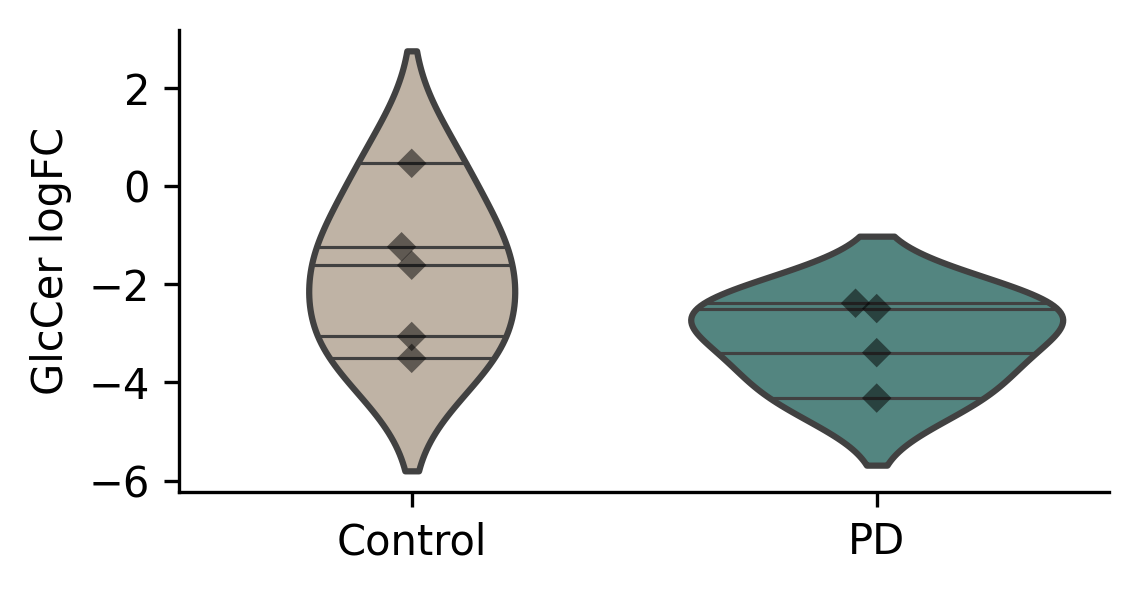

In [19]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(4, 2), dpi=300)
cat = 'Concentration_pmol'
ax = sns.violinplot(x = df_logFC["Group"], y = df_logFC['logFC'], inner="stick",  palette={"PD": "#4B8D86", "Control":"#C3B3A1"}, order = ['Control', 'PD'])
sns.despine(top = True, right = True)
sns.swarmplot(x = df_logFC["Group"], y = df_logFC['logFC'],  dodge=True, color = 'black', marker="D", alpha=.5, order = ['Control', 'PD'])
#plt.legend(bbox_to_anchor=(1, 1), loc='upper left', borderaxespad=0.1)
ax.set_xlabel('')
ax.set_ylabel('GlcCer logFC')
plt.savefig('../../plots/06_validation_lipids/GlcCer_violin_logFC.png', bbox_inches = 'tight', dpi = 300)
plt.savefig('../../plots/06_validation_lipids/GlcCer_violin_logFC.pdf', bbox_inches = 'tight', dpi = 300)
plt.show()

In [23]:
df_logFC[df_logFC["Group"]=='PD'].mean()

/home/MinaRyten/Melissa/MRIxST/code/06_validation_lipids/ipykernel_144995/4286285760.py:1: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  df_logFC[df_logFC["Group"]=='PD'].mean()


logFC   -3.147041
dtype: float64

In [24]:
df_logFC[df_logFC["Group"]=='Control'].mean()

/home/MinaRyten/Melissa/MRIxST/code/06_validation_lipids/ipykernel_144995/2547692406.py:1: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  df_logFC[df_logFC["Group"]=='Control'].mean()


logFC   -1.788907
dtype: float64

In [8]:
# Perform paired analyses

list_tests = []
for comp in categories:
    paired_filtered = PD_paired[[col for col in PD_paired.columns if comp in col]]
    paired_filtered.dropna(inplace = True)
    #print(comp)
    #print(np.shape(paired_filtered))
    if np.shape(paired_filtered)[0]<3:
        #print(f"Skipping {comp}: only {paired_filtered.shape[0]} samples")
        continue
    else:
        res = stats.ttest_rel(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        #res = wilcoxon(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        list_tests.append(comp)
        if comp == categories[0]:
            total_res = pd.DataFrame(res).T
        else:
            total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)


total_res.rename(columns = {0:'statistic',1:'pval'}, inplace = True)
total_res.index = list_tests
total_res.dropna(inplace = True)
total_res['padj'] = sm.fdrcorrection(list(total_res['pval']), alpha=0.05, method='indep', is_sorted=False)[1]

sig = total_res[total_res['pval']<0.05]

/home/MinaRyten/Melissa/MRIxST/code/06_validation_lipids/ipykernel_144995/440169113.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)


In [9]:
sig

,statistic,pval,padj
Concentration_pmol,3.750633,0.033102,0.033102


In [10]:
# Perform paired analyses

list_tests = []
for comp in categories:
    paired_filtered = Ctrl_paired[[col for col in Ctrl_paired.columns if comp in col]]
    paired_filtered.dropna(inplace = True)
    #print(comp)
    #print(np.shape(paired_filtered))
    if np.shape(paired_filtered)[0]<3:
        #print(f"Skipping {comp}: only {paired_filtered.shape[0]} samples")
        continue
    else:
        res = stats.ttest_rel(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        #res = wilcoxon(paired_filtered[paired_filtered.columns[0]], paired_filtered[paired_filtered.columns[1]])
        list_tests.append(comp)
        if comp == categories[0]:
            total_res = pd.DataFrame(res).T
        else:
            total_res = pd.concat([total_res, pd.DataFrame(res).T], axis = 0)


total_res.rename(columns = {0:'statistic',1:'pval'}, inplace = True)
total_res.index = list_tests
total_res.dropna(inplace = True)
total_res['padj'] = sm.fdrcorrection(list(total_res['pval']), alpha=0.05, method='indep', is_sorted=False)[1]

sig = total_res[total_res['pval']<0.05]

/home/MinaRyten/Melissa/MRIxST/code/06_validation_lipids/ipykernel_144995/2742827955.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  paired_filtered.dropna(inplace = True)


In [11]:
sig

,statistic,pval,padj


In [12]:
total_res

,statistic,pval,padj
Concentration_pmol,2.109009,0.102605,0.102605


In [13]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(4, 4), dpi=300)

for cat in list(sig.index):
    ax = sns.violinplot(x = df["Condition"], y = df[cat], hue = df["Location"], inner="stick",  palette={"Surface": "#ED5E70", "Deep":"#66CCEE"})
    sns.despine(top = True, right = True)
    sns.swarmplot(x = df["Condition"], y = df[cat], hue = df["Location"], dodge=True, color = 'black', marker="D", alpha=.5)
    plt.legend(bbox_to_anchor=(1, 1), loc='upper left', borderaxespad=0.1)
    ax.set_xlabel('')
    plt.savefig('../../plots/06_validation_lipids/GlcCer_violin_significant.png', bbox_inches = 'tight', dpi = 300)
    plt.savefig('../../plots/06_validation_lipids/GlcCer_violin_significant.pdf', bbox_inches = 'tight', dpi = 300)
    plt.show()

<Figure size 1200x1200 with 0 Axes>

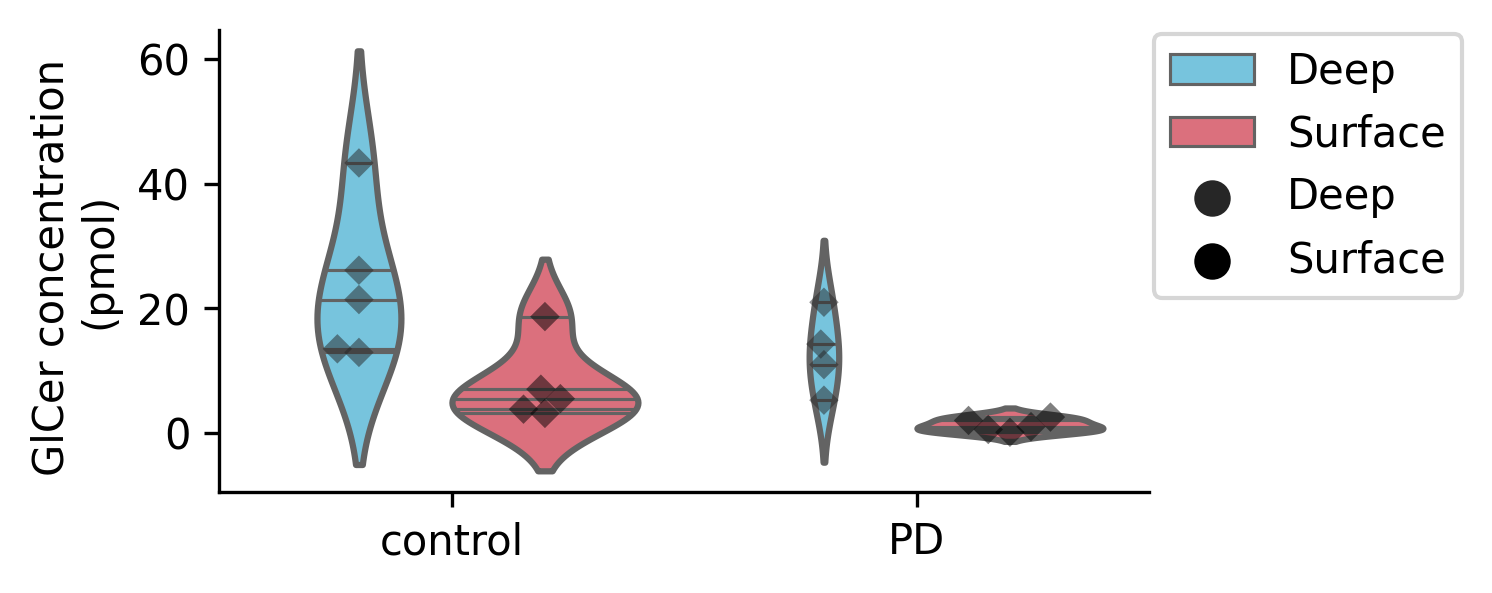

In [14]:
## PLOT SURFACE/DEEP DIFFERENCES

plt.figure(figsize=(4, 2), dpi=300)
cat = 'Concentration_pmol'
ax = sns.violinplot(x = df["Condition"], y = df[cat], hue = df["Location"], inner="stick",  palette={"Surface": "#ED5E70", "Deep":"#66CCEE"})
sns.despine(top = True, right = True)
sns.swarmplot(x = df["Condition"], y = df[cat], hue = df["Location"], dodge=True, color = 'black', marker="D", alpha=.5)
plt.legend(bbox_to_anchor=(1, 1), loc='upper left', borderaxespad=0.1)
ax.set_xlabel('')
ax.set_ylabel('GlCer concentration \n(pmol)')
plt.savefig('../../plots/06_validation_lipids/GlcCer_violin_significant.png', bbox_inches = 'tight', dpi = 300)
plt.savefig('../../plots/06_validation_lipids/GlcCer_violin_significant.pdf', bbox_inches = 'tight', dpi = 300)
plt.show()

In [15]:
print('Surface: ', stats.ttest_ind(surface[surface['Condition_surface']=='PD']['Concentration_pmol_surface'], surface[surface['Condition_surface']=='control']['Concentration_pmol_surface']))
deep = deep.dropna()
print('Deep: ', stats.ttest_ind(deep[deep['Condition_deep']=='PD']['Concentration_pmol_deep'], deep[deep['Condition_deep']=='control']['Concentration_pmol_deep']))

Surface:  Ttest_indResult(statistic=-2.2180598628188792, pvalue=0.05735542289667264)
Deep:  Ttest_indResult(statistic=-1.5301818051869158, pvalue=0.16982457129156397)
